# Fitness app users — 02 Cleaning and exploratory analysis

Eric Gomez · November 2026

This notebook applies the decisions from `01`, measures what each data problem would have changed if it had been
kept, and describes the cleaned data: how the fields are distributed, how they relate, and whether any
demographic group behaves differently. Its figures are the evidence that `03` tests formally and that `04`
builds models on.

In [1]:
import sys, pathlib

ROOT = pathlib.Path.cwd()
ROOT = ROOT.parent if ROOT.name == 'notebooks' else ROOT
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.visualization.theme import PALETTE, save_fig, set_plot_style
set_plot_style()
pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 30)

In [2]:
from src.data.fitness import (GENDERS, LOCATIONS, RAW_FILE, TIER_COLORS, TIERS,
                              AGE_LABELS, clean_users)
from src.data.loading import load_raw, save_processed

raw = load_raw(RAW_FILE)
users = clean_users(raw)            # notebook 01's decisions are the defaults
print(f'{len(raw):,} raw records -> {len(users):,} users')
print('distance available for', int(users['distance_km'].notna().sum()), 'users;',
      users['distance_flag'].value_counts().to_dict())
_ = save_processed(users, 'users.csv')
users.head()

5,299 raw records -> 5,000 users
distance available for 4997 users; {'': 4997, 'suspected x10 entry error (blank)': 2, 'missing': 1}
wrote data/processed/users.csv  (5000 rows)


,user_id,gender,age,activity_level,location,app_sessions,distance_km,calories,distance_flag,km_per_session,kcal_per_session,age_band
0,1,Female,22,Active,Suburban,151.0,140.0,728,,0.927152,4.821192,18–29
1,2,Male,50,Active,Rural,157.0,115.0,523,,0.732484,3.331210,50–59
2,3,Male,36,Active,Urban,178.0,163.0,795,,0.915730,4.466292,30–39
3,4,Female,36,Active,Suburban,155.0,85.0,715,,0.548387,4.612903,30–39
4,5,Male,34,Sedentary,Rural,95.0,71.0,439,,0.747368,4.621053,30–39


### Interpretation

- **5,299 records become 5,000 users.** The block of copies after ID 5000 is removed (`01`).
- **Distance is available for 4,997 users.** One value was missing in the raw file (user 4907) and two
  suspected ×10 entry errors are blanked (users 1999 and 2067). Each blank carries a `distance_flag`, so it is
  never mistaken for a measured value.
- **Three derived fields.** `km_per_session` and `kcal_per_session` separate *how often* a user opens the app
  from *how far* and *how hard* each session goes (DECISION 7 below). `age_band` groups age into ten-year bands
  for the group comparisons and for the privacy checks in `05`.
- **Where the cleaned table lives.** `data/processed/users.csv` stays on the analyst's machine and is not
  published with the repository, because it holds one row per person. The repository publishes aggregate
  tables and figures only (guideline G6 in `05`).

## Data validation and management matrix

Each problem from `01`, with its classification, the decision, and what keeping it would have changed. The
impacts are computed below, not estimated.

In [3]:
from src.data.fitness import COLUMNS
from sklearn.model_selection import train_test_split

FIELDS = ['gender', 'age', 'activity_level', 'location', 'app_sessions', 'distance_km', 'calories']
all_rows = clean_users(raw, drop_copy_block=False, suspect_distances='keep')
base = all_rows[all_rows['user_id'] < 5001]
block = all_rows[all_rows['user_id'] >= 5001]
key = lambda d: d[FIELDS].fillna(-1).astype(str).apply('|'.join, axis=1)
is_verbatim = key(block).isin(set(key(base)))
verbatim, altered = block[is_verbatim], block[~is_verbatim]

def share(d, col, level):
    return 100 * (d[col] == level).mean()

def twins_across_split(d, seed=803):
    """Test records with an exact copy in the training set, after a random 80/20 split."""
    tr, te = train_test_split(d, test_size=0.2, random_state=seed)
    return int(key(te).isin(set(key(tr))).sum()), len(te)

t_all, n_te_all = twins_across_split(all_rows)
t_clean, n_te_clean = twins_across_split(users)
kept_920 = clean_users(raw, suspect_distances='keep')
r = lambda d: d[['app_sessions', 'distance_km']].dropna().corr().iat[0, 1]

matrix = pd.DataFrame([
    {'problem': '272 of the 299 records in IDs 5001-5299: verbatim copies of users 3580-3855',
     'classification': 'Data-integrity error', 'decision': 'Remove; keep the source',
     'impact_if_kept': (f'Users 5,000 -> {len(base) + len(verbatim):,}; in a random 80/20 split, '
                        f'{t_all} of {n_te_all:,} test records would have an exact twin in training '
                        f'({t_clean} after cleaning), which inflates test scores (04)')},
    {'problem': '27 of the 299 records in IDs 5001-5299: altered copies (gender, location, sessions or calories changed)',
     'classification': 'Data-integrity error', 'decision': 'Remove; keep the source',
     'impact_if_kept': (f'27 users who do not exist; Male share {share(base, "gender", "Male"):.1f}% -> '
                        f'{share(pd.concat([base, block]), "gender", "Male"):.1f}% with the whole block; '
                        f'one calorie value at {altered["kcal_per_session"].max():.1f} kcal per session, '
                        'outside the 2-5 band')},
    {'problem': 'Distance 920 km from 182 sessions (user 1999)',
     'classification': 'Statistical outlier', 'decision': 'Blank the distance; keep the record',
     'impact_if_kept': (f'Pearson r(sessions, distance) {r(users):.3f} -> {r(kept_920):.3f}; '
                        f'SD of distance {users["distance_km"].std():.1f} -> {kept_920["distance_km"].std():.1f} km; '
                        f'max km per session 0.995 -> {kept_920["km_per_session"].max():.2f}')},
    {'problem': 'Distance 10 km from 119 sessions (user 2067)',
     'classification': 'Statistical outlier', 'decision': 'Blank the distance; keep the record',
     'impact_if_kept': (f'min km per session {users["km_per_session"].min():.2f} -> '
                        f'{kept_920["km_per_session"].min():.2f}; missed by the IQR and z-score screens')},
    {'problem': 'Distance blank (user 4907)', 'classification': 'Missing data',
     'decision': 'Leave blank; complete cases where distance is used',
     'impact_if_kept': 'None: one value in 5,000; models that use distance run on 4,997 users'},
])
from src.visualization.presentation import save_table
_ = save_table(matrix, '02_validation_matrix')

saved outputs/tables/02_validation_matrix.csv

                                                                                                problem       classification                                           decision                                                                                                                                                   impact_if_kept
                            272 of the 299 records in IDs 5001-5299: verbatim copies of users 3580-3855 Data-integrity error                            Remove; keep the source Users 5,000 -> 5,272; in a random 80/20 split, 89 of 1,060 test records would have an exact twin in training (0 after cleaning), which inflates test scores (04)
27 of the 299 records in IDs 5001-5299: altered copies (gender, location, sessions or calories changed) Data-integrity error                            Remove; keep the source                       27 users who do not exist; Male share 50.8% -> 50.9% with the whole block; one ca

### Interpretation

- **The copy block does the most damage, and the damage is hidden.** Kept, it adds 272 users who are exact
  copies of others. Means barely move, so the problem would not show in a summary table. It shows in model
  evaluation: in a random 80/20 split, 89 of the 1,060 test records would have an exact twin in the training
  set. A model would be scored on records it had already seen, and its test score would overstate how it
  performs on new users (quantified in `04`).
- **The altered copies are 27 users who do not exist.** Their changes are small in aggregate (the male share
  moves from 50.8% to 50.9%), but they create pairs of records that disagree about the same person, and one
  calorie value falls outside the 2–5 kcal-per-session band.
- **One wrong distance weakens a key relationship.** Keeping 920 km lowers the Pearson correlation between
  sessions and distance from 0.857 to 0.822 and inflates the spread of distance by 5% (SD 36.8 → 38.6 km).
  A single value is enough to move a correlation computed on 5,000 users.
- **The 10 km value changes no summary**, but it is the only record below 0.49 km per session, and it passes
  every one-column screen.

## DECISION 7 — derived fields

| Field | Formula | Reason |
|---|---|---|
| `km_per_session` | distance ÷ app sessions | Distance and calories grow with sessions (`01`). Dividing by sessions separates how far each session goes from how often the app is used |
| `kcal_per_session` | calories ÷ app sessions | The same, for energy: an intensity measure that does not simply restate frequency |
| `age_band` | 18–29, 30–39, 40–49, 50–59 | Equal ten-year bands (18–29 is twelve years, as the data start at 18). Used for group comparisons and as the generalised age in `05` |

Each ratio assumes distance and calories accumulate in proportion to sessions. The plots below check that
assumption.

In [4]:
from src.analysis.descriptive import describe_numeric

NUMS = ['app_sessions', 'distance_km', 'calories', 'age', 'km_per_session', 'kcal_per_session']
desc = describe_numeric(users, NUMS)
display(desc)
cats = pd.concat({c: users[c].value_counts().rename('n').to_frame().assign(
                      pct=lambda d: (100 * d['n'] / d['n'].sum()).round(1))
                  for c in ['gender', 'activity_level', 'location', 'age_band']})
cats.index.names = ['variable', 'level']
_ = save_table(desc.reset_index().rename(columns={'index': 'variable'}), '02_descriptives')
_ = save_table(cats.reset_index(), '02_categories')

,count,missing,mean,std,variance,min,25%,50%,75%,max,range
app_sessions,5000.0,0,124.3664,42.6893,1822.3778,50.0000,89.0000,124.0000,161.0000,199.0000,149.0000
distance_km,4997.0,3,92.5453,36.7560,1351.0070,26.0000,63.0000,89.0000,118.0000,195.0000,169.0000
calories,5000.0,0,432.3160,187.4274,35129.0400,102.0000,285.0000,406.0000,560.0000,987.0000,885.0000
age,5000.0,0,38.4236,12.1606,147.8809,18.0000,28.0000,39.0000,49.0000,59.0000,41.0000
km_per_session,4997.0,3,0.7449,0.1442,0.0208,0.4906,0.6207,0.7458,0.8684,0.9948,0.5043
kcal_per_session,5000.0,0,3.4722,0.8678,0.7531,2.0000,2.7177,3.4704,4.2113,4.9945,2.9945


saved outputs/tables/02_descriptives.csv

        variable  count  missing     mean      std   variance      min      25%      50%      75%      max    range
    app_sessions 5000.0        0 124.3664  42.6893  1822.3778  50.0000  89.0000 124.0000 161.0000 199.0000 149.0000
     distance_km 4997.0        3  92.5453  36.7560  1351.0070  26.0000  63.0000  89.0000 118.0000 195.0000 169.0000
        calories 5000.0        0 432.3160 187.4274 35129.0400 102.0000 285.0000 406.0000 560.0000 987.0000 885.0000
             age 5000.0        0  38.4236  12.1606   147.8809  18.0000  28.0000  39.0000  49.0000  59.0000  41.0000
  km_per_session 4997.0        3   0.7449   0.1442     0.0208   0.4906   0.6207   0.7458   0.8684   0.9948   0.5043
kcal_per_session 5000.0        0   3.4722   0.8678     0.7531   2.0000   2.7177   3.4704   4.2113   4.9945   2.9945
saved outputs/tables/02_categories.csv

      variable     level    n  pct
        gender      Male 2538 50.8
        gender    Female 2462 49.2
a

### Interpretation

- **Balanced by design.** Gender is 50.8% male and 49.2% female; each activity level and location type holds
  33–35% of users. The age bands hold 23–29%, and the largest band, 18–29, is also the only twelve-year band.
  So ages are spread evenly from 18 to 59.
- **Engagement.** Users opened the app 124 times on average (SD 43, range 50–199), travelled 92.5 km
  (SD 36.8) and burned 432 kcal (SD 187).
- **Per-session rates.** Distance per session averages 0.745 km (range 0.49–0.99) and calories per session
  3.47 kcal (range 2.00–4.99). Both ranges are narrow, and neither has a tail.

saved outputs/figures/02_distributions.png


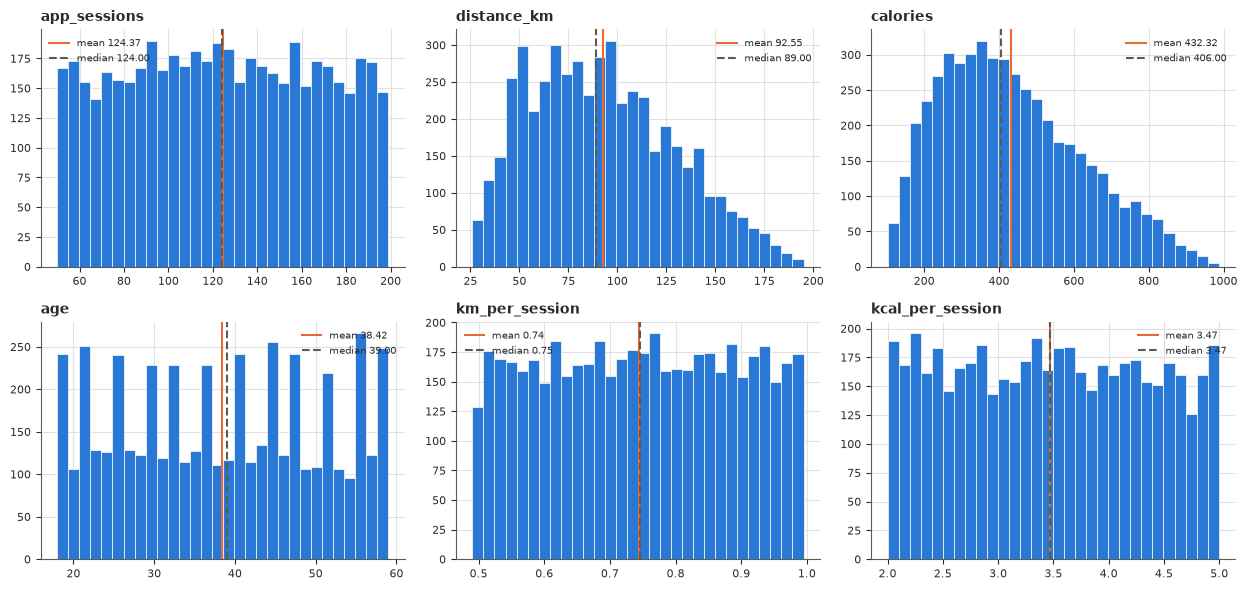

In [5]:
from src.visualization.plots import distribution_grid

fig, _ = distribution_grid(users, NUMS, bins=30, ncols=3)
save_fig(fig, '02_distributions')
plt.show()

### Interpretation

- **Sessions, age and both per-session rates are flat.** Each histogram is close to a rectangle: every value in
  the range is about equally common.
- **Distance and calories are hump-shaped and skewed right.** They are products of two flat quantities
  (sessions × a per-session rate), and a product of flat quantities piles up in the middle.
- **Why it matters for the methods.** Flat and skewed shapes are not normal. Rank-based summaries and tests
  are used where shape matters (DECISION 4, `03`); the regression models in `04` are judged by out-of-sample
  error, which needs no normality assumption.

## The structure of engagement

saved outputs/figures/02_A_engagement_structure.png


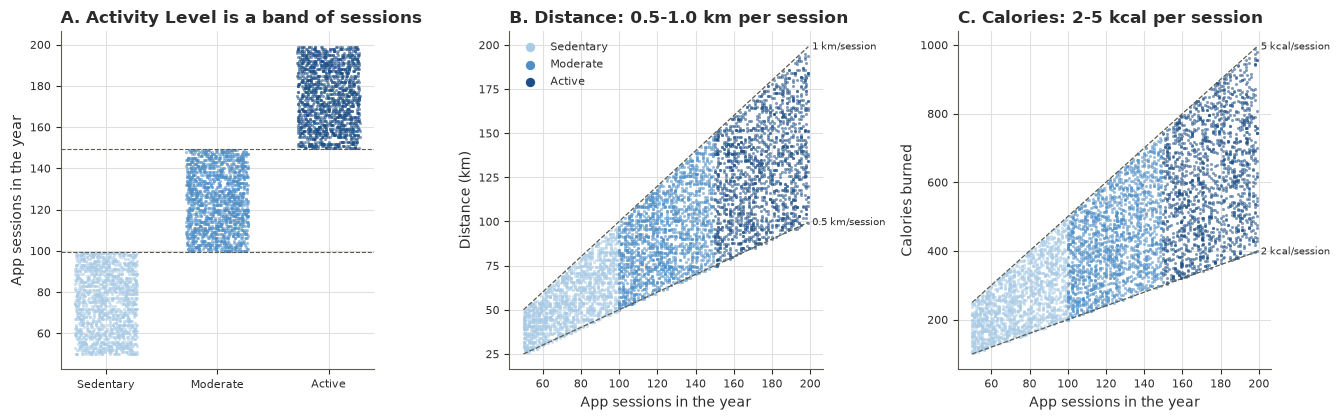

In [6]:
rng = np.random.default_rng(803)
d = users.dropna(subset=['distance_km'])
fig, axes = plt.subplots(1, 3, figsize=(13.5, 4.3))

ax = axes[0]
for i, t in enumerate(TIERS):
    s = users.loc[users['activity_level'] == t, 'app_sessions']
    ax.scatter(i + rng.uniform(-0.28, 0.28, len(s)), s, s=5, alpha=0.55, color=TIER_COLORS[t], lw=0)
for edge in (99.5, 149.5):
    ax.axhline(edge, color=PALETTE['rule'], lw=0.8, ls='--')
ax.set_xticks(range(3), TIERS)
ax.set_ylabel('App sessions in the year')
ax.set_title('A. Activity Level is a band of sessions')

for ax, y, lo, hi, unit, title in [
        (axes[1], 'distance_km', 0.5, 1.0, 'km', 'B. Distance: 0.5-1.0 km per session'),
        (axes[2], 'calories', 2.0, 5.0, 'kcal', 'C. Calories: 2-5 kcal per session')]:
    for t in TIERS:
        part = d[d['activity_level'] == t]
        ax.scatter(part['app_sessions'], part[y], s=5, alpha=0.55, color=TIER_COLORS[t], lw=0, label=t)
    xs = np.array([50, 199])
    ax.plot(xs, lo * xs, color=PALETTE['rule'], lw=0.9, ls='--')
    ax.plot(xs, hi * xs, color=PALETTE['rule'], lw=0.9, ls='--')
    ax.text(201, lo * 199, f'{lo:g} {unit}/session', fontsize=7.5, va='center')
    ax.text(201, hi * 199, f'{hi:g} {unit}/session', fontsize=7.5, va='center')
    ax.set_xlabel('App sessions in the year')
    ax.set_ylabel('Distance (km)' if y == 'distance_km' else 'Calories burned')
    ax.set_title(title)
leg = axes[1].legend(markerscale=3, loc='upper left')
for h in leg.legend_handles:
    h.set_alpha(1)
fig.tight_layout()
save_fig(fig, '02_A_engagement_structure')
plt.show()

### Interpretation

- **A. Activity Level is three non-overlapping bands of sessions.** The dashed lines at 100 and 150 sessions
  separate the tiers completely, as found in `01`.
- **B. Distance stays between 0.5 and 1.0 km per session.** Every user sits inside the wedge between the two
  dashed lines, and the wedge widens as sessions rise.
- **C. Calories stay between 2 and 5 kcal per session**, again in a widening wedge.
- **The widening matters.** The spread of calories among users with 185–199 sessions is about three and a
  half times the spread among users with 50–55 sessions (SD 158 against 46 kcal). Any prediction of calories is therefore much less certain for frequent users than for occasional
  ones, and a single error band for all users would mislead both groups (`04`).

In [7]:
from scipy import stats

rows = []
for t, (lo, hi) in zip(TIERS, [(50, 99), (100, 149), (150, 199)]):
    s = users.loc[users['activity_level'] == t, 'app_sessions'].astype(int)
    counts = s.value_counts().reindex(range(lo, hi + 1), fill_value=0)
    chi2, p = stats.chisquare(counts)
    rows.append({'quantity': f'sessions within {t} ({lo}-{hi})', 'test': 'chi-square vs discrete uniform',
                 'statistic': chi2, 'p_value': p, 'n': len(s)})
for col, lo, hi in [('km_per_session', 0.5, 1.0), ('kcal_per_session', 2.0, 5.0)]:
    x = users[col].dropna()
    D, p = stats.kstest(x, stats.uniform(lo, hi - lo).cdf)
    rows.append({'quantity': f'{col} vs uniform({lo:g}, {hi:g})', 'test': 'Kolmogorov-Smirnov D',
                 'statistic': D, 'p_value': p, 'n': len(x)})
structure = pd.DataFrame(rows)
display(structure.round(4))

rates = users[['app_sessions', 'km_per_session', 'kcal_per_session']].dropna()
print('Spearman correlations between the three per-user rates:')
display(rates.corr(method='spearman').round(3))
_ = save_table(structure, '02_structure_tests')

,quantity,test,statistic,p_value,n
0,sessions within Sedentary (50-99),chi-square vs discrete uniform,53.3929,0.3092,1634
1,sessions within Moderate (100-149),chi-square vs discrete uniform,30.2445,0.9839,1734
2,sessions within Active (150-199),chi-square vs discrete uniform,43.1225,0.7092,1632
3,"km_per_session vs uniform(0.5, 1)",Kolmogorov-Smirnov D,0.0155,0.1765,4997
4,"kcal_per_session vs uniform(2, 5)",Kolmogorov-Smirnov D,0.0181,0.0744,5000


Spearman correlations between the three per-user rates:


,app_sessions,km_per_session,kcal_per_session
app_sessions,1.000,-0.013,0.013
km_per_session,-0.013,1.000,0.005
kcal_per_session,0.013,0.005,1.000


saved outputs/tables/02_structure_tests.csv

                          quantity                           test  statistic  p_value    n
 sessions within Sedentary (50-99) chi-square vs discrete uniform  53.392901 0.309220 1634
sessions within Moderate (100-149) chi-square vs discrete uniform  30.244521 0.983858 1734
  sessions within Active (150-199) chi-square vs discrete uniform  43.122549 0.709238 1632
 km_per_session vs uniform(0.5, 1)           Kolmogorov-Smirnov D   0.015550 0.176501 4997
 kcal_per_session vs uniform(2, 5)           Kolmogorov-Smirnov D   0.018108 0.074426 5000


### Interpretation

- **Sessions are spread evenly inside each tier.** The chi-square tests against a flat distribution give
  p = 0.31, 0.98 and 0.71.
- **Both per-session rates are flat between fixed limits.** The largest gap between each rate's distribution
  and a flat one (the Kolmogorov–Smirnov D) is under two percentage points: 0.016 for km per session (p = 0.18)
  and 0.018 for kcal per session (p = 0.07).
- **The three rates are independent.** Their pairwise Spearman correlations are between −0.013 and 0.013.
- **What this means.** Every record is consistent with three independent draws:
  - a session count, flat across its tier's range;
  - a distance per session, flat between 0.5 and 1.0 km;
  - a calorie rate, flat between 2 and 5 kcal per session.

  Data recorded from real people are rarely this regular, so the file looks generated by a simple simulation.
  That has two consequences for the rest of the analysis:
  - **Hard ceilings.** Calories can be predicted only as well as "3.5 kcal × sessions", because the calorie
    rate is an independent draw that no other field reveals (`04`).
  - **Negligible demographic effects expected.** If age, gender and location played no part in generating the data,
    any demographic effect should be practically negligible in this dataset (`03` tests this formally).

## DECISION 4 — correlation method

**Spearman.** The relationships are monotonic, but the spread grows with sessions, and sessions and age are flat
rather than normal (above). Spearman's rank correlation measures a monotonic association without assuming
linearity or normality (Bruce et al., 2020). Pearson's r is used only where a linear model is fitted (`04`).

saved outputs/figures/02_correlations.png


,app_sessions,distance_km,calories,age,km_per_session,kcal_per_session
app_sessions,1.000,0.874,0.813,-0.002,-0.013,0.013
distance_km,0.874,1.000,0.718,-0.001,0.450,0.013
calories,0.813,0.718,1.000,0.001,-0.010,0.566
age,-0.002,-0.001,0.001,1.000,-0.007,-0.006
km_per_session,-0.013,0.450,-0.010,-0.007,1.000,0.005
kcal_per_session,0.013,0.013,0.566,-0.006,0.005,1.000


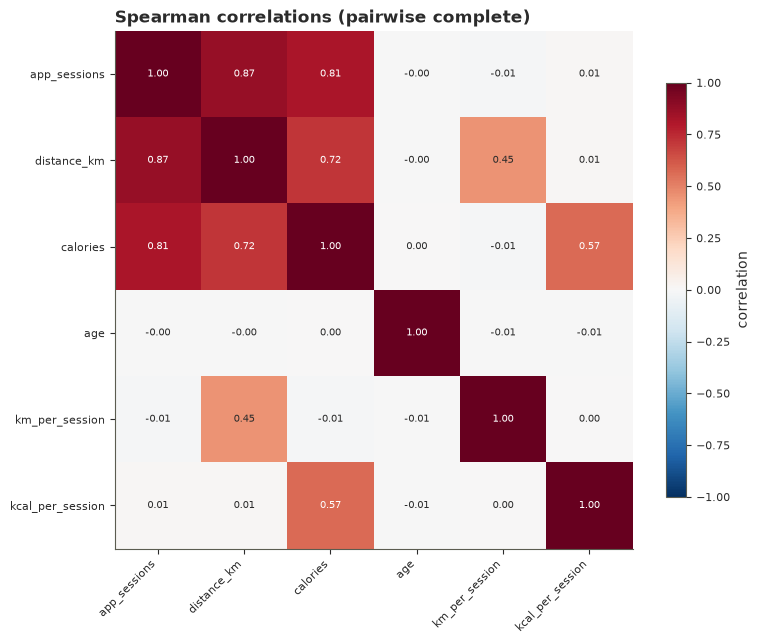

In [8]:
from src.analysis.correlation import correlation_matrix
from src.visualization.plots import correlation_heatmap

corr = correlation_matrix(users, method='spearman', columns=NUMS)
fig, _ = correlation_heatmap(corr, title='Spearman correlations (pairwise complete)')
save_fig(fig, '02_correlations')
display(corr.round(3))
plt.show()

### Interpretation

- **The totals move together.** Sessions correlate with distance (ρ = 0.87) and calories (ρ = 0.81), and distance
  with calories (ρ = 0.72). The last link exists only through sessions: per session, distance and calories are
  unrelated (ρ = 0.005).
- **Age correlates with nothing** (every |ρ| ≤ 0.007).
- **Each rate correlates with its own total and nothing else.** km per session correlates with distance
  (ρ = 0.45) and kcal per session with calories (ρ = 0.57), as they must, but neither correlates with sessions.
  Frequency and intensity are separate dimensions of behaviour.

## Demographic groups

saved outputs/figures/02_B_demographic_profile.png


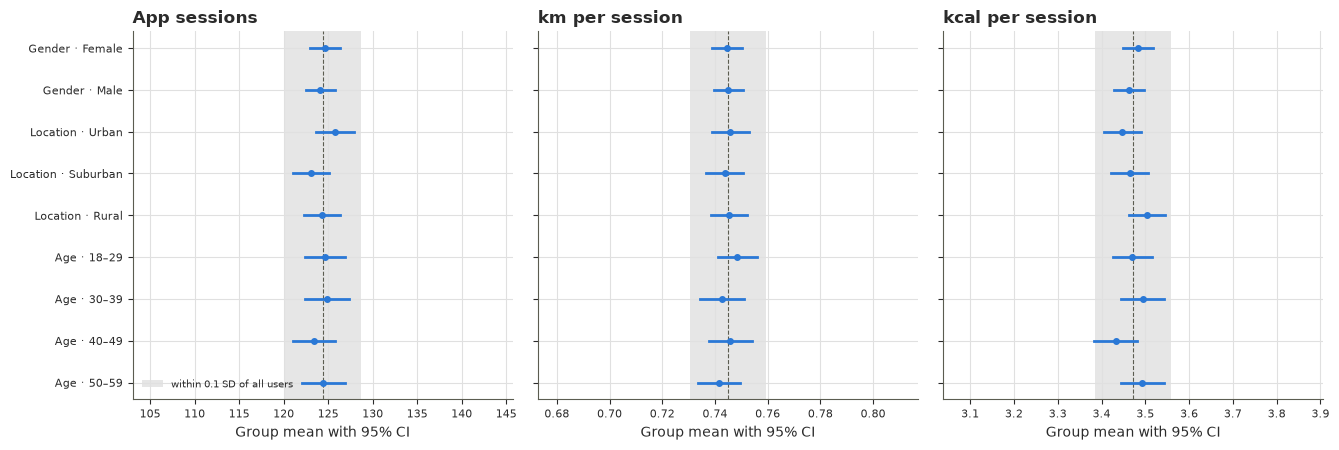

95% intervals reaching beyond the 0.1 SD band: [('kcal per session', 'age_band', '40–49')]
saved outputs/tables/02_demographic_profile.csv

         outcome attribute    group    n     mean   ci_low  ci_high  overall_mean
    App sessions    gender   Female 2462 124.6190 122.9218 126.3163      124.3664
    App sessions    gender     Male 2538 124.1214 122.4708 125.7719      124.3664
    App sessions  location    Urban 1638 125.7924 123.6647 127.9201      124.3664
    App sessions  location Suburban 1678 123.0298 121.0129 125.0466      124.3664
    App sessions  location    Rural 1684 124.3112 122.3067 126.3157      124.3664
    App sessions  age_band    18–29 1460 124.6712 122.4330 126.9094      124.3664
    App sessions  age_band    30–39 1156 124.8901 122.4372 127.3431      124.3664
    App sessions  age_band    40–49 1217 123.4100 121.0022 125.8178      124.3664
    App sessions  age_band    50–59 1167 124.4636 122.0837 126.8434      124.3664
  km per session    gender   Female 2461

In [9]:
from scipy import stats

OUTCOMES = [('app_sessions', 'App sessions'), ('km_per_session', 'km per session'),
            ('kcal_per_session', 'kcal per session')]
ATTRS = [('gender', GENDERS), ('location', LOCATIONS), ('age_band', AGE_LABELS)]

def mean_ci(x):
    x = x.dropna()
    m, se = x.mean(), x.std(ddof=1) / np.sqrt(len(x))
    return m, m - 1.96 * se, m + 1.96 * se, len(x)

prof = []
for col, label in OUTCOMES:
    overall = users[col].mean()
    for attr, levels in ATTRS:
        for lvl in levels:
            m, lo, hi, n = mean_ci(users.loc[users[attr] == lvl, col])
            prof.append({'outcome': label, 'attribute': attr, 'group': lvl, 'n': n,
                         'mean': m, 'ci_low': lo, 'ci_high': hi, 'overall_mean': overall})
prof = pd.DataFrame(prof)

ATTR_LABEL = {'gender': 'Gender', 'location': 'Location', 'age_band': 'Age'}
fig, axes = plt.subplots(1, 3, figsize=(13.5, 4.6), sharey=True)
ylabels = [f'{ATTR_LABEL[a]} · {g}' for a, levels in ATTRS for g in levels]
ypos = {lab: i for i, lab in enumerate(ylabels[::-1])}
for ax, (col, label) in zip(axes, OUTCOMES):
    part = prof[prof['outcome'] == label]
    overall, sd = part['overall_mean'].iat[0], users[col].std()
    # Shaded: within 0.1 SD of the all-user mean, the conventional "negligible" difference.
    ax.axvspan(overall - 0.1 * sd, overall + 0.1 * sd, color=PALETTE['grid'], alpha=0.8, lw=0,
               label='within 0.1 SD of all users')
    ax.axvline(overall, color=PALETTE['rule'], lw=0.8, ls='--')
    for _, r in part.iterrows():
        y = ypos[f"{ATTR_LABEL[r['attribute']]} · {r['group']}"]
        ax.plot([r['ci_low'], r['ci_high']], [y, y], color=PALETTE['accent'], lw=2)
        ax.plot(r['mean'], y, 'o', color=PALETTE['accent'], ms=4)
    ax.set_xlim(overall - 0.5 * sd, overall + 0.5 * sd)      # fixed scale: half an SD either side
    ax.set_title(label)
    ax.set_xlabel('Group mean with 95% CI')
axes[0].set_yticks(list(ypos.values()), list(ypos.keys()))
axes[0].legend(loc='lower left', fontsize=7.5)
fig.tight_layout()
save_fig(fig, '02_B_demographic_profile')
plt.show()
inside = [(r['outcome'], r['attribute'], r['group']) for _, r in prof.iterrows()
          if not (abs(r['ci_low'] - r['overall_mean']) <= 0.1 * users[{'App sessions': 'app_sessions',
                  'km per session': 'km_per_session', 'kcal per session': 'kcal_per_session'}[r['outcome']]].std()
                  and abs(r['ci_high'] - r['overall_mean']) <= 0.1 * users[{'App sessions': 'app_sessions',
                  'km per session': 'km_per_session', 'kcal per session': 'kcal_per_session'}[r['outcome']]].std())]
print('95% intervals reaching beyond the 0.1 SD band:', inside if inside else 'none')
_ = save_table(prof.round(4), '02_demographic_profile')

### Interpretation

- **No demographic group stands out.** For sessions, distance per session and calories per session, every group
  mean is close to the all-user mean (dashed line), and every 95% interval crosses it.
- **The differences are negligible, not just non-significant.** The shaded band marks 0.1 standard deviations
  either side of the all-user mean, the conventional threshold below which a difference is negligible (Cohen,
  1988). Every interval lies inside the band except one: calories per session for ages 40–49, whose lower end
  falls 0.001 kcal outside it.
- **Scale.** Each panel spans half a standard deviation either side of the mean, so the visible gaps are drawn
  at their true size, not zoomed in. `03` tests these comparisons formally.

In [10]:
summ = (users.groupby('activity_level', observed=True)
        .agg(n=('user_id', 'size'), sessions=('app_sessions', 'mean'), distance_km=('distance_km', 'mean'),
             calories=('calories', 'mean'), km_per_session=('km_per_session', 'mean'),
             kcal_per_session=('kcal_per_session', 'mean'), age=('age', 'mean'),
             male_pct=('gender', lambda g: 100 * (g == 'Male').mean()))
        .round(2))
display(summ)
_ = save_table(summ.reset_index(), '02_tier_summary')

,n,sessions,distance_km,calories,km_per_session,kcal_per_session,age,male_pct
activity_level,,,,,,,,
Active,1632,174.20,129.29,606.00,0.74,3.48,38.21,49.75
Moderate,1734,124.16,92.55,432.08,0.75,3.48,38.62,52.19
Sedentary,1634,74.81,55.89,259.10,0.75,3.46,38.43,50.24


saved outputs/tables/02_tier_summary.csv

activity_level    n  sessions  distance_km  calories  km_per_session  kcal_per_session   age  male_pct
        Active 1632    174.20       129.29    606.00            0.74              3.48 38.21     49.75
      Moderate 1734    124.16        92.55    432.08            0.75              3.48 38.62     52.19
     Sedentary 1634     74.81        55.89    259.10            0.75              3.46 38.43     50.24


### Interpretation

- **The tiers differ in one thing only.** Mean sessions are 75, 124 and 174, so distance and calories rise with
  them. But distance per session (0.74–0.75 km), calories per session (3.46–3.48 kcal), mean age (38.2–38.6)
  and the male share (49.8–52.2%) are the same in every tier.
- **The label measures how often the app is used**, not how hard or how far people exercise. An Active user
  works no harder per session than a Sedentary one.

## Relationships ruled out

- Age, gender and location show no association with frequency, distance per session or intensity.
- Frequency does not predict intensity: frequent users do not run further or burn more per session.
- Distance per session does not predict calories per session.

## Summary for `03` and `04`

1. The cleaned data are 5,000 users (4,997 with a distance), with the validation matrix above as the record of
   every change.
2. *Activity Level* is a band of *App Sessions*. It must not be predicted from sessions (target leakage).
3. Distance and calories are sessions multiplied by independent per-session rates, so the spread of both grows
   with sessions.
4. No demographic group differs in any behaviour. `03` tests whether these differences are negligible, not
   just undetected.

## References

Bruce, P., Bruce, A., & Gedeck, P. (2020). *Practical statistics for data scientists: 50+ essential concepts
using R and Python* (2nd ed.). O'Reilly Media.

Cohen, J. (1988). *Statistical power analysis for the behavioral sciences* (2nd ed.). Lawrence Erlbaum
Associates.